# Model Experiments: Kryptonite-20, -30 and -40

The paper makes three claims about Kryptonite-n that this notebook tests:

1. Polynomial logistic regression stays below 59% up to degree 10, so polynomial basis expansion fails ("a counterexample to universal approximation").
2. Quadrupling the training data does not help.
3. Nothing reaches the 90% that counts as solving the dataset: even KryptoNet-40, an MLP pretrained on 200,000 examples of a related task and used frozen, scores worse than a coin flip.

The paper's Future Works suggests networks trained from scratch and tree-based models, and asks what degree and how many examples a polynomial would need.

KryptoNet-40 on Kryptonite-40-Adapt is the LoRA notebook's part. This notebook also picks one final pipeline per dataset, scores it on a locked test set and writes the hidden-set predictions to `hiddenlabels/`.

Each experiment's code is in its own script (`exp1_degree.py`, `exp2_from_scratch.py`, `exp3_weighted_kernel.py`, `exp4_data_size.py`, `final_pipeline.py`, `energy_report.py`), with the shared parts in `utils.py` and `models.py` (needs `codecarbon`). Each script also runs on its own, in this order, e.g. `python exp1_degree.py`. Results are cached in `exp_cache/` (git-ignored) so an interrupted run resumes; delete it for a fresh run. `KRYP_QUICK=1` runs a dry run on 3,000 rows whose numbers mean nothing.

In [1]:
import utils
import exp1_degree
import exp2_from_scratch
import exp3_weighted_kernel
import exp4_data_size
import final_pipeline
import energy_report

print(
    "QUICK dry run" if utils.QUICK else "Full run",
    f"- {utils.K}-fold CV on 80% of the rows, 20% locked test",
)

Full run - 5-fold CV on 80% of the rows, 20% locked test


## Data and Protocol

A stratified 20% of the labelled rows is locked away until the end. The other 80% (dev) is split into five stratified folds; every choice, including the bit weights of Experiment 3, is made on the training folds only. Accuracies are mean ± sd over the folds; two models are compared fold by fold. The locked-test accuracy has the binomial 95% interval p ± 1.96·√(p(1−p)/N).

The inputs are ±1 bits plus Gaussian noise, so every model uses the sign of each input, except the paper's baseline, which uses the raw inputs as in the paper.

In [2]:
utils.check_protocol()

n=20: 12000 labelled rows = 9600 dev (5 folds of 7680 train / 1920 validation rows) + 2400 locked; 0.496 positive; noise sd 0.100
n=30: 20000 labelled rows = 16000 dev (5 folds of 12800 train / 3200 validation rows) + 4000 locked; 0.499 positive; noise sd 0.100
n=40: 32000 labelled rows = 25600 dev (5 folds of 20480 train / 5120 validation rows) + 6400 locked; 0.498 positive; noise sd 0.100


## Experiment 1: Higher Degree on All Bits

*Claim 1.* *Hypothesis:* a higher degree does not help on all n bits, because the number of monomials grows far faster than the number of training rows.

Logistic regression on explicit monomials (products of distinct bits) with an L2 penalty, `C` chosen by CV, up to the largest degree that fits in memory (4, 3, 2 for n = 20, 30, 40). Beyond that, the paper's own polynomial kernel (`C = 0.85`, plus an intercept) at degrees 6, 10, 15, n and 2n. From degree n on, the kernel can represent every function of the bits. If it then fits the training rows perfectly but not the validation rows, the failure is one of generalisation, not of approximation.

In [3]:
exp1_degree.run()
exp1_degree.table_degree_all()

kernel tests passed
Polynomial LR on all bits: CV accuracy by degree (mean ± sd over folds)
                                               n = 20         n = 30         n = 40
--------------------------------------  -------------  -------------  -------------
Explicit monomials (best C per degree)
    degree 1                            0.495 ± 0.011  0.495 ± 0.009  0.499 ± 0.004
    degree 2                            0.548 ± 0.008  0.531 ± 0.010  0.534 ± 0.004
    degree 3                            0.554 ± 0.006  0.530 ± 0.005              -
    degree 4                            0.581 ± 0.004              -              -

The paper's kernel (C = 0.85)
    degree 6                            0.582 ± 0.010  0.545 ± 0.009  0.542 ± 0.007
    degree 10                           0.590 ± 0.010  0.549 ± 0.007  0.538 ± 0.008
    degree 15                           0.589 ± 0.009  0.544 ± 0.002  0.515 ± 0.004
    degree n                            0.595 ± 0.006  0.531 ± 0.005  0.502 ± 0.00

## Experiment 2: Models Trained From Scratch on All Bits

*Claim 3.* *Hypothesis:* each reaches over 90%. The two model types the paper's Future Works suggests, tuned by the same CV on all n bits:

- a random forest;
- an MLP with KryptoNet-40's architecture (four hidden layers of 512), trained from scratch on Kryptonite-n with Adam and early stopping. The paper only used this architecture pretrained on Kryptonite-40-Pre and frozen.

In [4]:
exp2_from_scratch.run_models()
exp2_from_scratch.table_families()

Trained from scratch on all bits: CV accuracy (mean ± sd over folds)
                                          n = 20         n = 30         n = 40
---------------------------------  -------------  -------------  -------------
Random forest                      0.824 ± 0.023  0.784 ± 0.028  0.786 ± 0.024
MLP 4×512                          0.931 ± 0.007  0.943 ± 0.009  0.949 ± 0.006
Best polynomial LR, for reference  0.595 ± 0.006  0.549 ± 0.007  0.542 ± 0.007
n = 20: best forest has max features 1.0, min leaf 5
n = 30: best forest has max features 1.0, min leaf 5
n = 40: best forest has max features 1.0, min leaf 5


### Ablations of the MLP

One change at a time to the MLP above, each scored on the first three folds and compared with it fold by fold:

- the raw noisy inputs instead of their signs, as the paper fed them;
- one hidden layer of 512 instead of four;
- four hidden layers of 64 instead of 512.

*Hypothesis:* neither the sign step nor KryptoNet-40's exact size is what makes the MLP work.

In [5]:
exp2_from_scratch.run_ablations()
exp2_from_scratch.table_ablations()

MLP ablations: accuracy on folds 1, 2, 3 of 5 (mean ± sd)
                                              n = 20                   n = 30                   n = 40
---------------------------  -----------------------  -----------------------  -----------------------
4×512 on the bits (above)              0.927 ± 0.007            0.942 ± 0.013            0.947 ± 0.007
4×512 on the raw inputs                0.921 ± 0.007            0.938 ± 0.005            0.943 ± 0.001
    minus 4×512 on the bits  -0.006 ± 0.001 (0 of 3)  -0.004 ± 0.016 (1 of 3)  -0.003 ± 0.006 (1 of 3)
1×512 on the bits                      0.855 ± 0.007            0.785 ± 0.014            0.735 ± 0.004
    minus 4×512 on the bits  -0.072 ± 0.010 (0 of 3)  -0.158 ± 0.027 (0 of 3)  -0.212 ± 0.004 (0 of 3)
4×64 on the bits                       0.732 ± 0.018            0.631 ± 0.013            0.656 ± 0.023
    minus 4×512 on the bits  -0.195 ± 0.023 (0 of 3)  -0.311 ± 0.024 (0 of 3)  -0.291 ± 0.030 (0 of 3)
Differences: me

## Experiment 3: The Polynomial Kernel With Forest-Weighted Bits

*Claim 1, and the paper's question of what a polynomial needs.* Experiment 1 penalises every monomial equally, as the paper does. The forest of Experiment 2 beats it on the same bits, and a forest only splits on bits that help it. *Hypothesis:* the label depends on a few of the n bits, and the polynomial fails because almost all its monomials involve the others, not because its degree is too low.

This is a two-stage method (MANBAT in the report), not the paper's estimator:

1. In each training fold, a random forest is fitted on three quarters of the training rows. Each bit's weight wᵢ is its permutation importance on the remaining quarter (Breiman, 2001): the drop in the forest's accuracy when that bit is shuffled. Negative importances are set to 0 and the largest weight is scaled to 1.
2. Logistic regression on all n bits with the polynomial kernel

$$k(x, x') = \left(\frac{1 + \sum_i w_i x_i x'_i}{1 + \sum_i w_i}\right)^d$$

The result is still a degree-d polynomial of the bits. The weights change only how strongly each monomial is penalised: monomials of low-weight bits are penalised more heavily, and a monomial containing a zero-weight bit is left out. Giving each input its own scale in a kernel is the idea behind automatic relevance determination (MacKay, 1994; Neal, 1996). The same kernel with every weight 1 is the comparison.

[codecarbon INFO @ 22:38:19] offline tracker init
[codecarbon WARNING @ 22:38:19] Multiple instances of codecarbon are allowed to run at the same time.


WK n=40 deg6 degree 6, C 100                                     0.915 ± 0.028  (2021.0s)
UK n=40 deg10 degree 10, C 10                                    0.531 ± 0.010  (119.1s)
WK n=40 deg10 degree 10, C 10                                    0.960 ± 0.002  (539.3s)
WK n=40 deg10 degree 10, C 100                                   0.958 ± 0.003  (1340.9s)
UK n=40 deg15 degree 15, C 10                                    0.504 ± 0.001  (97.9s)
WK n=40 deg15 degree 15, C 10                                    0.960 ± 0.002  (396.0s)
WK n=40 deg15 degree 15, C 100                                   0.958 ± 0.002  (1077.9s)
Bit weights from one random forest per training fold (permutation importance)
                                                   n = 20  n = 30  n = 40
-------------------------------------------------  ------  ------  ------
10 largest weights on the same bits in every fold     yes     yes     yes
Share of the total weight on those 10 bits          0.981   0.982   0.982
B

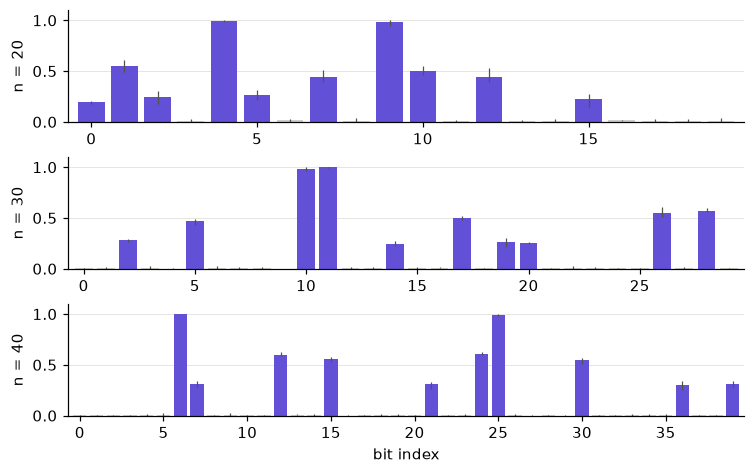

Bars: mean weight over folds (violet: the 10 largest); whiskers: smallest to largest fold.
Polynomial kernel LR on all bits: CV accuracy by degree (mean ± sd over folds)
                                                n = 20         n = 30         n = 40
---------------------------------------  -------------  -------------  -------------
Equal weights
    degree 6                             0.602 ± 0.010  0.552 ± 0.011  0.542 ± 0.009
    degree 10                            0.600 ± 0.005  0.554 ± 0.005  0.531 ± 0.010
    degree 15                            0.590 ± 0.009  0.539 ± 0.006  0.504 ± 0.001

Forest weights (best C per degree)
    degree 6                             0.881 ± 0.026  0.912 ± 0.025  0.915 ± 0.028
    degree 10                            0.942 ± 0.012  0.958 ± 0.008  0.960 ± 0.002
    degree 15                            0.954 ± 0.008  0.961 ± 0.004  0.960 ± 0.002
        training accuracy, best setting          0.967          0.967          0.963
n = 20: best we

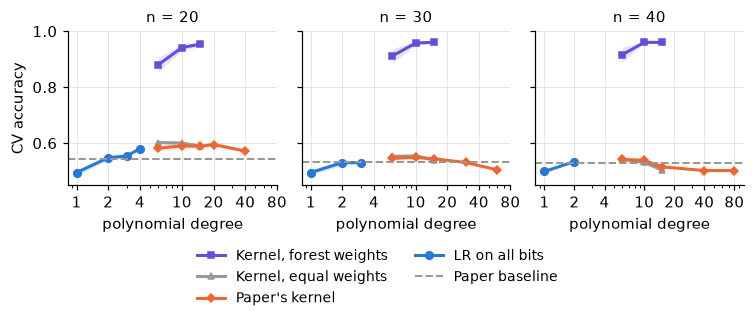

Mean over the folds (shaded: one sd), best setting at each degree.


In [6]:
exp3_weighted_kernel.run()
exp3_weighted_kernel.table_weights()
exp3_weighted_kernel.fig_weights()
exp3_weighted_kernel.table_weighted_kernel()
exp3_weighted_kernel.fig_degree()

## Experiment 4: Amount of Training Data

*Claim 2, and the paper's question of how many examples are needed.* The best model of each kind is trained on nested random subsets of the training folds (first three folds) and scored on the held-out fold; the weighted kernel computes its weights on the subset. For LR and the kernels, `C` is scaled with the number of rows so the penalty per row stays fixed.

LC n=20 deg15                                                    0.500 ± 0.016  (20.9s)
LC n=20 deg15                                                    0.530 ± 0.032  (5.2s)
LC n=20 deg15                                                    0.572 ± 0.040  (6.7s)
LC n=20 deg15                                                    0.767 ± 0.057  (9.9s)
LC n=20 deg15                                                    0.853 ± 0.027  (16.1s)
LC n=30 deg15                                                    0.503 ± 0.004  (5.7s)
LC n=30 deg15                                                    0.506 ± 0.025  (6.5s)
LC n=30 deg15                                                    0.512 ± 0.020  (7.6s)
LC n=30 deg15                                                    0.567 ± 0.033  (11.2s)
LC n=30 deg15                                                    0.733 ± 0.054  (21.5s)
LC n=40 deg15                                                    0.498 ± 0.003  (7.0s)
LC n=40 deg15                          

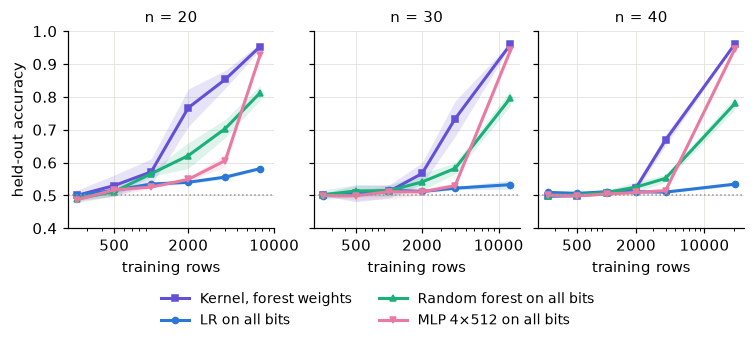

Mean over the first folds (shaded: one sd), each model at its CV-best setting. Dotted: 0.5


In [7]:
exp4_data_size.fig_learning_curves(exp4_data_size.run_learning_curves())

## Final Pipeline and Hidden-Set Predictions

The final pipeline per n is the candidate with the highest CV mean. It is refitted on all dev rows (its bit weights included) and scored once on the locked rows. Two controls, on the first three folds, must score about 0.5: the final pipeline with shuffled training labels (otherwise something leaks), and the best weighted kernel, whether or not it is the final pipeline, with its weights moved to the wrong bits, the largest on the least important (otherwise the weights are not what makes it work). `check_caps` lists any fit that stopped at its iteration limit.

For the hidden set the pipeline is refitted on all labelled rows. As the hidden labels are unknown, its predictions must agree with those of the best model of another kind that scores above 0.9 in CV: two models with error rates e₁ and e₂ can disagree on at most e₁ + e₂ of the rows, so a lower agreement (with 2 points of slack) stops the notebook. Then `hiddenlabels/y_predicted_{20,30,40}.npy` are written and checked with the course's `check_submission.py`.

In [8]:
FINAL = final_pipeline.choose_final()
final_pipeline.run_controls(FINAL)
final_pipeline.table_final(FINAL)
utils.check_caps()
print()
final_pipeline.predict_hidden(FINAL)

n = 20: Weighted kernel LR, degree 15 (degree 15, C 10)
n = 30: Weighted kernel LR, degree 15 (degree 15, C 10)
n = 40: Weighted kernel LR, degree 15 (degree 15, C 10)
FINAL n=20 deg15                                                 0.952 ± 0.000  (32.3s)
FINAL n=30 deg15                                                 0.958 ± 0.000  (76.8s)
FINAL n=40 deg15                                                 0.959 ± 0.000  (183.4s)

Final pipeline
                                                                           n = 20                   n = 30                   n = 40
--------------------------------------------------------  -----------------------  -----------------------  -----------------------
CV accuracy on dev (mean ± sd)                                      0.954 ± 0.008            0.961 ± 0.004            0.960 ± 0.002
Locked test accuracy                                                        0.952                    0.958                    0.959
    95% interval       

## Summary

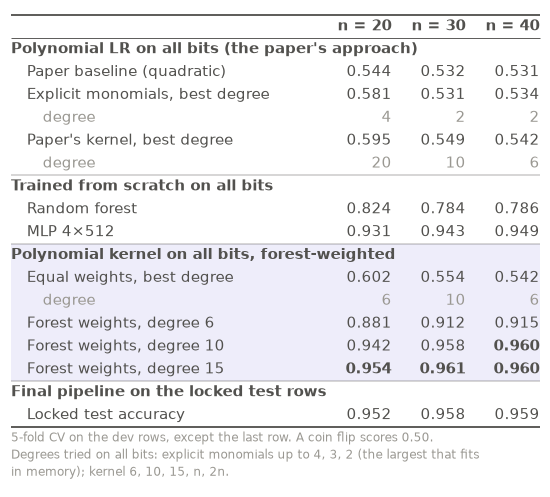

In [9]:
final_pipeline.fig_summary_table(FINAL)

## Energy and Emissions

CPU energy measured with CodeCarbon while each result was computed, from the processor's own energy counters (the whole package, so other programs should be closed). Every model runs on the CPU only, so no GPU energy is counted; RAM and screen are not measured. If the CPU counters cannot be read, nothing is reported. Emissions use the GB grid's 2024 average, 125 g CO2 per kWh (NESO, *Britain's Electricity Explained: 2024 Review*).

In [10]:
energy_report.carbon_report()

Measured CPU energy by experiment
                                          hours  CPU Wh  g CO2e
----------------------------------------  -----  ------  ------
Polynomial LR on all bits                  0.08     1.0     0.1
Kernel LR on all bits                      0.21     3.9     0.5
Random forest on all bits                  0.04     0.7     0.1
MLP 4×512                                  1.96    30.9     3.9
Kernel on all bits, equal weights          0.14     2.3     0.3
Kernel on all bits, forest weights         2.68    63.9     8.0
MLP ablations                              0.96    17.6     2.2
Learning curves                            0.17     3.6     0.4
Bit weights                                0.04     0.9     0.1
Final pipeline: controls and locked test   0.33     7.3     0.9
Hidden-set refits                          0.27     5.4     0.7
Total                                      6.88   137.6    17.2
CPU: Intel(R) Core(TM) i9-14900HX; energy read from its own counters (